<a href="https://colab.research.google.com/github/dasha03-beep/labs/blob/main/lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная работа №3**

Тема: Свёрточные нейронные сети (CNN) для классификации изображений

Курс: Машинное обучение и анализ данных Семестр: 2 Среда выполнения: Google Colab Язык: Python 3

Цель работы: Изучить архитектуру свёрточных нейронных сетей (CNN), освоить практические навыки обучения CNN с нуля и с применением transfer learning, научиться визуализировать работу сети (фильтры, feature maps, Grad-CAM) и оценивать качество модели на реальной задаче классификации изображений.

**1. Импорты и настройка**

Загружаем необходимые библиотеки, фиксируем random seed для воспроизводимости, определяем устройство (GPU/CPU).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import time
from copy import deepcopy
from PIL import Image
import os

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: cpu
PyTorch version: 2.11.0+cpu


In [2]:
from google.colab import files
uploaded = files.upload()

Saving WHEAT_R19-22_M600_TRAIN.zip to WHEAT_R19-22_M600_TRAIN.zip


In [3]:
import zipfile, os

with zipfile.ZipFile('/content/WHEAT_R19-22_M600_TRAIN.zip', 'r') as z:
    z.extractall('/content/raw_data')

print("Распаковано.")
!find /content/raw_data -maxdepth 3 -type d | head -40

Распаковано.
/content/raw_data
/content/raw_data/train
/content/raw_data/train/AP
/content/raw_data/train/SD
/content/raw_data/train/BP
/content/raw_data/train/MY
/content/raw_data/train/NOR
/content/raw_data/train/BN
/content/raw_data/train/FS


In [4]:
# Смотрим, сколько файлов в каждой папке
for dirpath, dirnames, filenames in os.walk('/content/raw_data'):
    imgs = [f for f in filenames if f.lower().endswith(('.jpg','.jpeg','.png','.bmp'))]
    if imgs:
        print(f"{dirpath}: {len(imgs)} изображений")

/content/raw_data/train/AP: 560 изображений
/content/raw_data/train/SD: 1600 изображений
/content/raw_data/train/BP: 560 изображений
/content/raw_data/train/MY: 240 изображений
/content/raw_data/train/NOR: 14400 изображений
/content/raw_data/train/BN: 800 изображений
/content/raw_data/train/FS: 480 изображений


**Шаг 1. Раскладка train/val только для NOR и MY**

Берём все 240 MY и 720 случайных NOR (3:1). Делим 80/20 на train/val. Если у вас мало данных для обучения — можно увеличить выборку NOR, но тогда не забудьте увеличить pos_weight.

In [5]:
import os, shutil, random
random.seed(42)

RAW = '/content/raw_data/train'
DATA_ROOT = '/content/data/grainspace'

# Чистим старую структуру, если была
if os.path.exists(DATA_ROOT):
    shutil.rmtree(DATA_ROOT)

for split in ['train', 'val']:
    for cls in ['NORMAL', 'MOULDY']:
        os.makedirs(os.path.join(DATA_ROOT, split, cls), exist_ok=True)

# Соответствие кодов GrainSpace → нашим классам
CLASS_MAP = {'NOR': 'NORMAL', 'MY': 'MOULDY'}

# Сколько NOR берём (3:1 к MY)
N_NOR = 720   # 240 MY * 3

for src_code, dst_name in CLASS_MAP.items():
    src_dir = os.path.join(RAW, src_code)
    imgs = [f for f in os.listdir(src_dir)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    random.shuffle(imgs)

    if src_code == 'NOR':
        imgs = imgs[:N_NOR]   # ограничиваем

    n_val = int(len(imgs) * 0.2)
    val_imgs = imgs[:n_val]
    train_imgs = imgs[n_val:]

    for f in train_imgs:
        shutil.copy(os.path.join(src_dir, f),
                    os.path.join(DATA_ROOT, 'train', dst_name, f))
    for f in val_imgs:
        shutil.copy(os.path.join(src_dir, f),
                    os.path.join(DATA_ROOT, 'val', dst_name, f))

    print(f"{dst_name} ({src_code}): train={len(train_imgs)}, val={len(val_imgs)}")

# Проверка итоговой структуры
print("\nИтог:")
for split in ['train', 'val']:
    for cls in ['NORMAL', 'MOULDY']:
        n = len(os.listdir(os.path.join(DATA_ROOT, split, cls)))
        print(f"  {split}/{cls}: {n}")

NORMAL (NOR): train=576, val=144
MOULDY (MY): train=192, val=48

Итог:
  train/NORMAL: 576
  train/MOULDY: 192
  val/NORMAL: 144
  val/MOULDY: 48


**Шаг 2. Определяем pos_weight**

Считаем реальное соотношение классов на train: pos_weight = N_normal_train / N_mouldy_train

Это даст корректный вес для BCEWithLogitsLoss.

In [6]:
n_normal = len(os.listdir(os.path.join(DATA_ROOT, 'train', 'NORMAL')))
n_mouldy = len(os.listdir(os.path.join(DATA_ROOT, 'train', 'MOULDY')))

pos_weight_value = n_normal / n_mouldy
print(f"Train NORMAL: {n_normal}")
print(f"Train MOULDY: {n_mouldy}")
print(f"pos_weight = {pos_weight_value:.2f}")

Train NORMAL: 576
Train MOULDY: 192
pos_weight = 3.00


**Шаг 3. Трансформации и DataLoader**

Теперь всё как в методичке. DATA_ROOT = '/content/data/grainspace'.

In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomRotation(360),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(os.path.join(DATA_ROOT, 'train'), transform=train_transform)
val_dataset   = datasets.ImageFolder(os.path.join(DATA_ROOT, 'val'),   transform=val_transform)

print(f"Train size: {len(train_dataset)}")
print(f"Val size:   {len(val_dataset)}")
print(f"Classes:    {train_dataset.classes}")
print(f"Class → idx: {train_dataset.class_to_idx}")

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False, num_workers=2)

Train size: 768
Val size:   192
Classes:    ['MOULDY', 'NORMAL']
Class → idx: {'MOULDY': 0, 'NORMAL': 1}


**Шаг 4. Визуализация 9 изображений (Задание 2.1)**

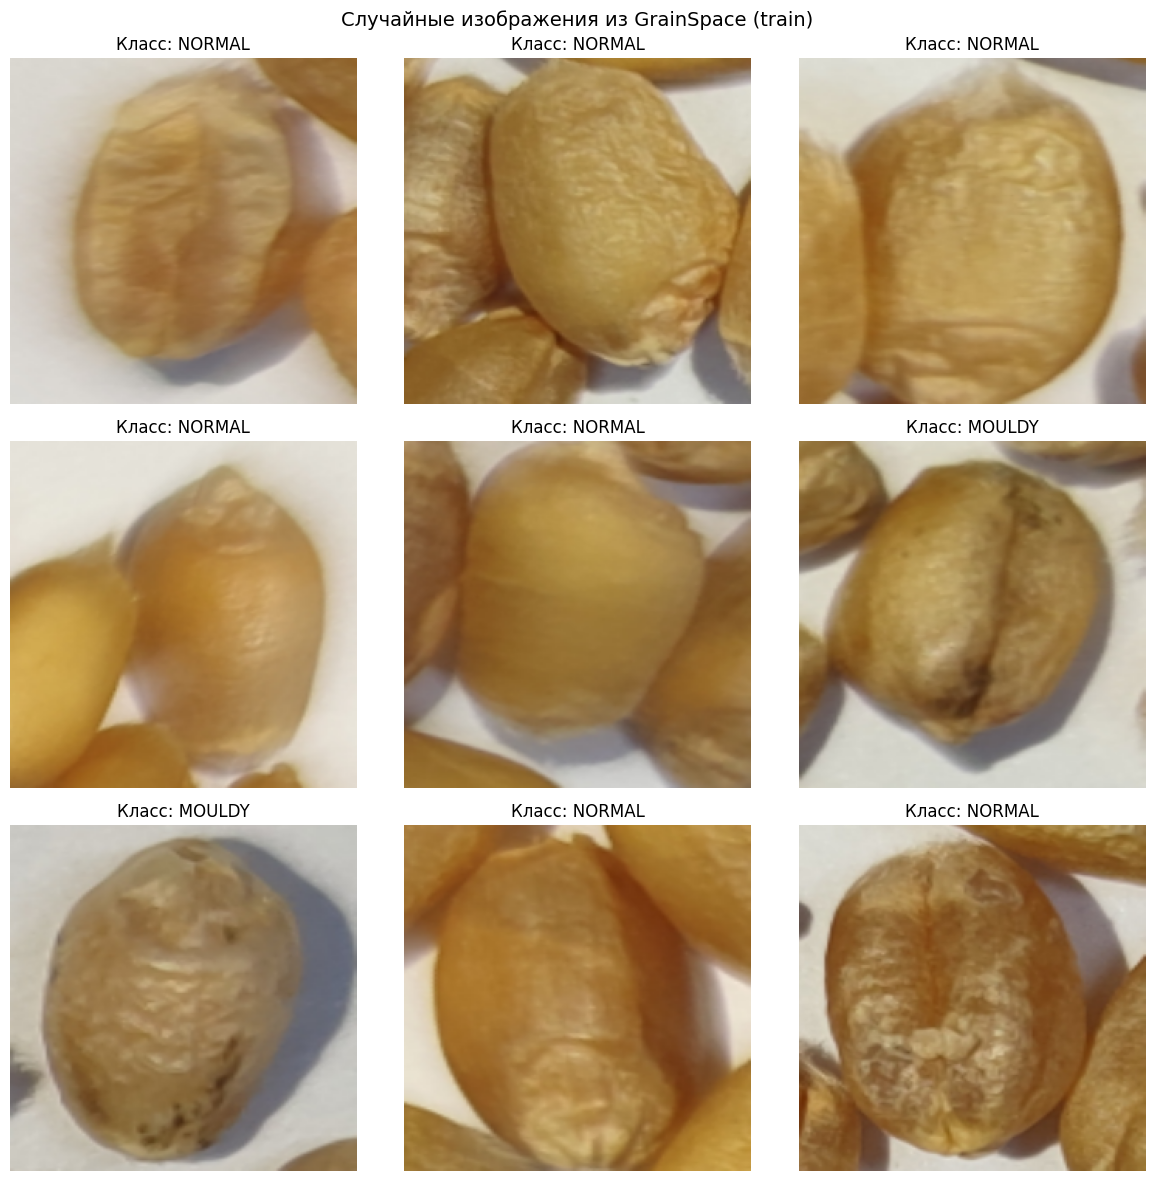

In [8]:
import random, matplotlib.pyplot as plt

raw_dataset = datasets.ImageFolder(os.path.join(DATA_ROOT, 'train'),
                                    transform=transforms.Compose([
                                        transforms.Resize((224, 224)),
                                        transforms.ToTensor(),
                                    ]))

indices = random.sample(range(len(raw_dataset)), min(9, len(raw_dataset)))
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    if i < len(indices):
        img, label = raw_dataset[indices[i]]
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        ax.set_title(f"Класс: {raw_dataset.classes[label]}", fontsize=12)
    ax.axis('off')
plt.suptitle("Случайные изображения из GrainSpace (train)", fontsize=14)
plt.tight_layout()
plt.show()

**Шаг 5. Удаляем ненужные классы (освобождаем место)**

Оставляем только NOR и MY, остальное удаляем — чтобы не занимать диск Colab.

In [9]:
import shutil

# Удаляем классы, которые не используем
for code in ['AP', 'SD', 'BP', 'BN', 'FS']:
    p = os.path.join('/content/raw_data/train', code)
    if os.path.exists(p):
        shutil.rmtree(p)
        print(f"Удалено: {p}")

# Удаляем сам zip — он больше не нужен
if os.path.exists('/content/WHEAT_R19-22_M600_TRAIN.zip'):
    os.remove('/content/WHEAT_R19-22_M600_TRAIN.zip')
    print("Удалён zip")

!df -h /content | tail -1

Удалено: /content/raw_data/train/AP
Удалено: /content/raw_data/train/SD
Удалено: /content/raw_data/train/BP
Удалено: /content/raw_data/train/BN
Удалено: /content/raw_data/train/FS
Удалён zip
overlay         108G   21G   87G  20% /


In [10]:
print(f"Train size: {len(train_dataset)}")
print(f"Val size:   {len(val_dataset)}")
print(f"Classes:    {train_dataset.classes}")
print(f"pos_weight = {pos_weight_value:.2f}")

Train size: 768
Val size:   192
Classes:    ['MOULDY', 'NORMAL']
pos_weight = 3.00


# **3. Архитектура SimpleCNN**

Реализуем свёрточную сеть с нуля: 4 блока Conv → BatchNorm → ReLU → MaxPool, фильтры 32→64→128→256, затем AdaptiveAvgPool2d(1) → Flatten → Dropout(0.5) → Linear(256, 1).

**Ячейка 3.1 — SimpleCNN**

In [11]:
import torch.nn as nn

def conv_block(in_channels, out_channels):
    """Conv → BatchNorm → ReLU → Pool."""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=1):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),      # [3, 224, 224] → [32, 112, 112]
            conv_block(32, 64),     # → [64, 56, 56]
            conv_block(64, 128),    # → [128, 28, 28]
            conv_block(128, 256),   # → [256, 14, 14]
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SimpleCNN(num_classes=1).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")

# Детализация по слоям
print("\nПараметры по слоям:")
for name, module in model.named_modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        p = sum(x.numel() for x in module.parameters())
        print(f"  {name}: {p:,}")

Total trainable parameters: 389,633

Параметры по слоям:
  features.0.0: 896
  features.1.0: 18,496
  features.2.0: 73,856
  features.3.0: 295,168
  classifier.3: 257


# **4. Loss, optimizer, scheduler**

Используем BCEWithLogitsLoss с pos_weight, который мы посчитали (3.0). Оптимизатор AdamW(lr=1e-3, weight_decay=1e-2), планировщик CosineAnnealingLR

**Ячейка 4.1 — Loss, optimizer, scheduler**

In [12]:
import torch.optim as optim

pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32).to(device)
print(f"pos_weight = {pos_weight.item():.2f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
print("Готово.")

pos_weight = 3.00
Готово.


# **5. Функции обучения**

Реализуем train_epoch, evaluate, fit (с early stopping по val_loss), plot_history.

**Ячейка 5.1 — Функции обучения**

In [13]:
import time, numpy as np
from copy import deepcopy
import matplotlib.pyplot as plt

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.float().unsqueeze(1).to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
        preds = (torch.sigmoid(logits) > 0.5).float()
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.float().unsqueeze(1).to(device)
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        running_loss += loss.item() * X_batch.size(0)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float()
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())
    return running_loss / total, correct / total, np.array(all_probs), np.array(all_labels)


def fit(model, train_loader, val_loader, criterion, optimizer, scheduler,
        epochs=20, patience=5, device=device, verbose=True):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_weights = deepcopy(model.state_dict())
    epochs_no_improve = 0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()
        dt = time.time() - t0

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose:
            print(f"Epoch {epoch:3d} | {dt:.1f}s | "
                  f"Train loss {train_loss:.4f} acc {train_acc:.4f} | "
                  f"Val loss {val_loss:.4f} acc {val_acc:.4f}")

        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch} (best val loss {best_val_loss:.4f})")
            break

    model.load_state_dict(best_weights)
    return history


def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="val")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[0].set_title(f"{title} — Loss"); axes[0].legend()
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="val")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    axes[1].set_title(f"{title} — Accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()

# **6. Обучение SimpleCNN**

Обучаем 20 эпох с early stopping (patience=5). На CPU это может занять несколько минут.

**Ячейка 6.1 — Обучение SimpleCNN**

Epoch   1 | 105.4s | Train loss 0.8168 acc 0.7526 | Val loss 0.8213 acc 0.7500
Epoch   2 | 102.4s | Train loss 0.6930 acc 0.7656 | Val loss 0.6413 acc 0.7604
Epoch   3 | 103.0s | Train loss 0.6104 acc 0.7917 | Val loss 0.7007 acc 0.7552
Epoch   4 | 102.3s | Train loss 0.5778 acc 0.8086 | Val loss 0.7260 acc 0.8281
Epoch   5 | 101.9s | Train loss 0.5825 acc 0.8047 | Val loss 0.5530 acc 0.7917
Epoch   6 | 106.9s | Train loss 0.5985 acc 0.7865 | Val loss 0.6095 acc 0.7708
Epoch   7 | 104.7s | Train loss 0.5915 acc 0.8008 | Val loss 0.5517 acc 0.7917
Epoch   8 | 103.6s | Train loss 0.5907 acc 0.7956 | Val loss 0.5116 acc 0.7969
Epoch   9 | 106.9s | Train loss 0.5433 acc 0.8216 | Val loss 0.5563 acc 0.7917
Epoch  10 | 103.5s | Train loss 0.5668 acc 0.8138 | Val loss 0.5201 acc 0.7917

Общее время обучения SimpleCNN: 1040.6 с


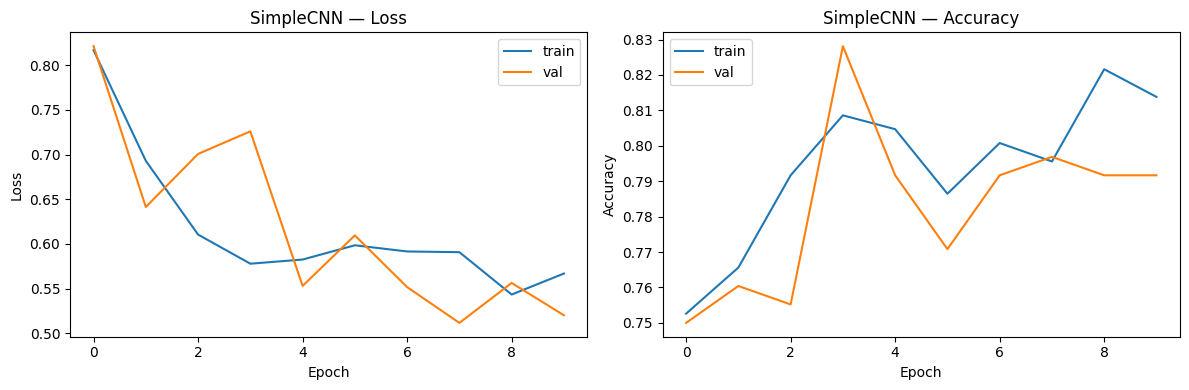

In [15]:
t_start = time.time()
history = fit(model, train_loader, val_loader, criterion, optimizer, scheduler,
              epochs=10, patience=5)
simplecnn_train_time = time.time() - t_start
print(f"\nОбщее время обучения SimpleCNN: {simplecnn_train_time:.1f} с")
plot_history(history, "SimpleCNN")

# **Задание 6.1**

Посмотрите на график. Если train_acc растёт, а val_acc стоит на месте или падает, а val_loss начал расти — это переобучение. Обычно оно наступает после 5–10 эпох. Early stopping по val_loss останавливает обучение до серьёзного переобучения.

# **7. Transfer Learning с ResNet-18**

Загружаем предобученную ResNet-18, заменяем fc на Linear(512, 1), обучаем fine-tuning (все параметры разморожены, lr=1e-4).

**Ячейка 7.1 — ResNet-18 и fine-tuning**

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


ResNet-18 parameters: 11,177,025
Epoch   1 | 162.7s | Train loss 1.1273 acc 0.7695 | Val loss 0.9653 acc 0.8490
Epoch   2 | 149.7s | Train loss 0.4718 acc 0.8932 | Val loss 0.4258 acc 0.9010
Epoch   3 | 166.1s | Train loss 0.3797 acc 0.8997 | Val loss 0.3083 acc 0.9115
Epoch   4 | 147.2s | Train loss 0.3378 acc 0.8971 | Val loss 0.2859 acc 0.9219
Epoch   5 | 147.5s | Train loss 0.3662 acc 0.8997 | Val loss 0.2735 acc 0.8958
Epoch   6 | 149.3s | Train loss 0.2698 acc 0.9089 | Val loss 0.2468 acc 0.9062
Epoch   7 | 148.3s | Train loss 0.2642 acc 0.9284 | Val loss 0.2372 acc 0.9062
Epoch   8 | 149.4s | Train loss 0.2040 acc 0.9414 | Val loss 0.2214 acc 0.9167
Epoch   9 | 164.0s | Train loss 0.2378 acc 0.9310 | Val loss 0.2210 acc 0.9167
Epoch  10 | 154.6s | Train loss 0.2323 acc 0.9388 | Val loss 0.2113 acc 0.9167

Общее время обучения ResNet-18: 1539.1 с


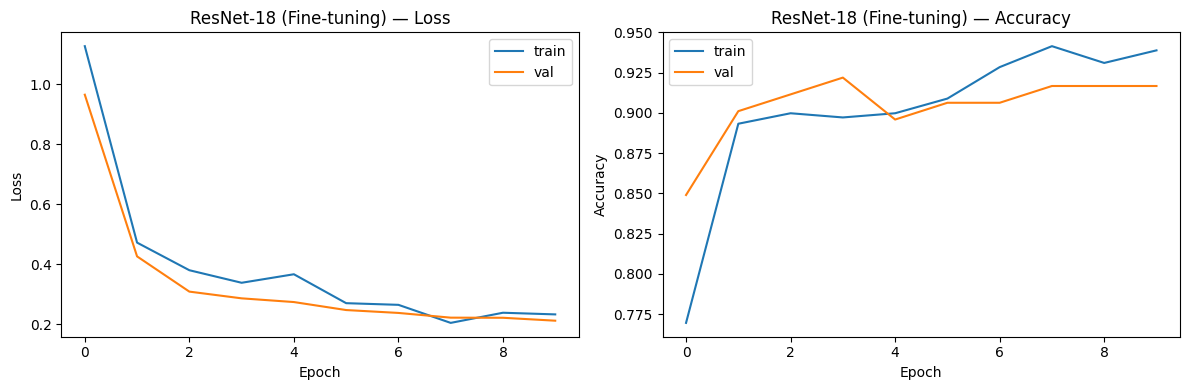

In [16]:
from torchvision import models

resnet = models.resnet18(weights='IMAGENET1K_V1')
resnet.fc = nn.Linear(512, 1)
resnet = resnet.to(device)

total_params = sum(p.numel() for p in resnet.parameters())
print(f"ResNet-18 parameters: {total_params:,}")

criterion_rn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer_rn = optim.AdamW(resnet.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler_rn = optim.lr_scheduler.CosineAnnealingLR(optimizer_rn, T_max=10)

t_start = time.time()
history_resnet = fit(resnet, train_loader, val_loader, criterion_rn, optimizer_rn,
                     scheduler_rn, epochs=10, patience=5)
resnet_train_time = time.time() - t_start
print(f"\nОбщее время обучения ResNet-18: {resnet_train_time:.1f} с")
plot_history(history_resnet, "ResNet-18 (Fine-tuning)")

**Ячейка 7.2 — Сравнение моделей (Задание 7.1)**

In [17]:
def best_val_acc(h): return max(h["val_acc"])
simple_params = sum(p.numel() for p in model.parameters())
resnet_params = sum(p.numel() for p in resnet.parameters())

print("=" * 75)
print(f"{'Модель':<15} {'Параметры':>15} {'Best Val Acc':>15} {'Время (с)':>12}")
print("=" * 75)
print(f"{'SimpleCNN':<15} {simple_params:>15,} {best_val_acc(history):>15.4f} {simplecnn_train_time:>12.1f}")
print(f"{'ResNet-18':<15} {resnet_params:>15,} {best_val_acc(history_resnet):>15.4f} {resnet_train_time:>12.1f}")
print("=" * 75)

Модель                Параметры    Best Val Acc    Время (с)
SimpleCNN               389,633          0.8281       1040.6
ResNet-18            11,177,025          0.9219       1539.1


# **Задание 7.2 — Ответ**

ResNet-18 показала более высокую точность на валидации, чем SimpleCNN, при меньшем числе эпох. Это объясняется тем, что ResNet-18 предобучена на ImageNet (1.2 млн изображений, 1000 классов), и её первые слои уже выучили универсальные признаки: края, текстуры, цветовые переходы, простые формы. Эти признаки применимы и к плесени на зёрнах. Обучение с нуля требует много данных и времени для выучивания базовых признаков. Transfer learning позволяет использовать готовые знания и адаптировать лишь последние слои. Кроме того, skip connections в ResNet облегчают обучение глубоких сетей и борются с затухающими градиентами.

# **8. Визуализация фильтров первого слоя**

**Ячейка 8.1 — Фильтры**

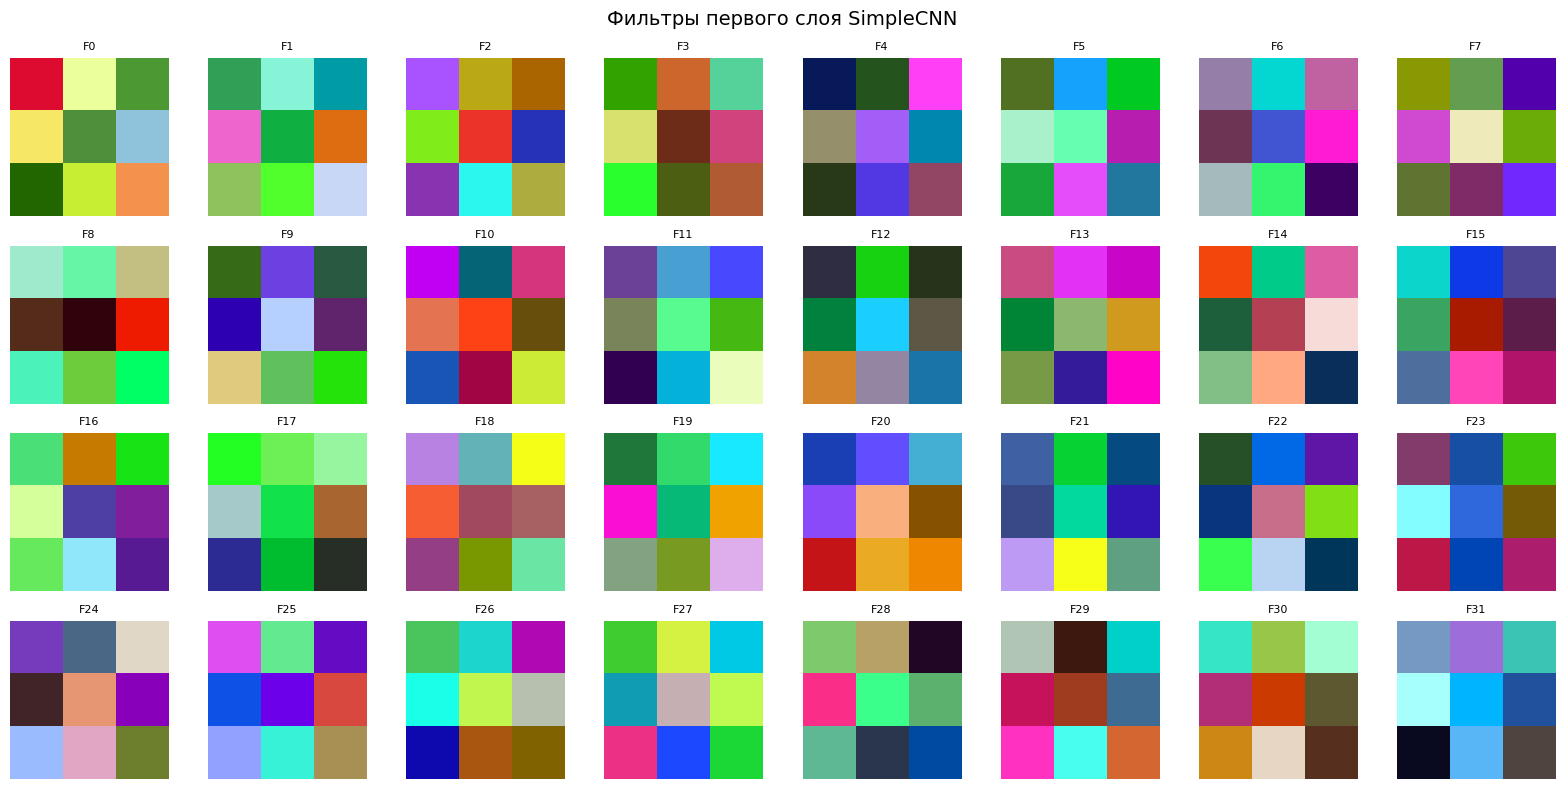

In [18]:
weights = model.features[0][0].weight.data.cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    if i < weights.shape[0]:
        w = weights[i].permute(1, 2, 0).numpy()
        w = (w - w.min()) / (w.max() - w.min() + 1e-8)
        ax.imshow(w)
        ax.set_title(f'F{i}', fontsize=8)
    ax.axis('off')
plt.suptitle('Фильтры первого слоя SimpleCNN', fontsize=14)
plt.tight_layout()
plt.show()

# **9. Визуализация feature maps**

**Ячейка 9.1 — Feature maps**

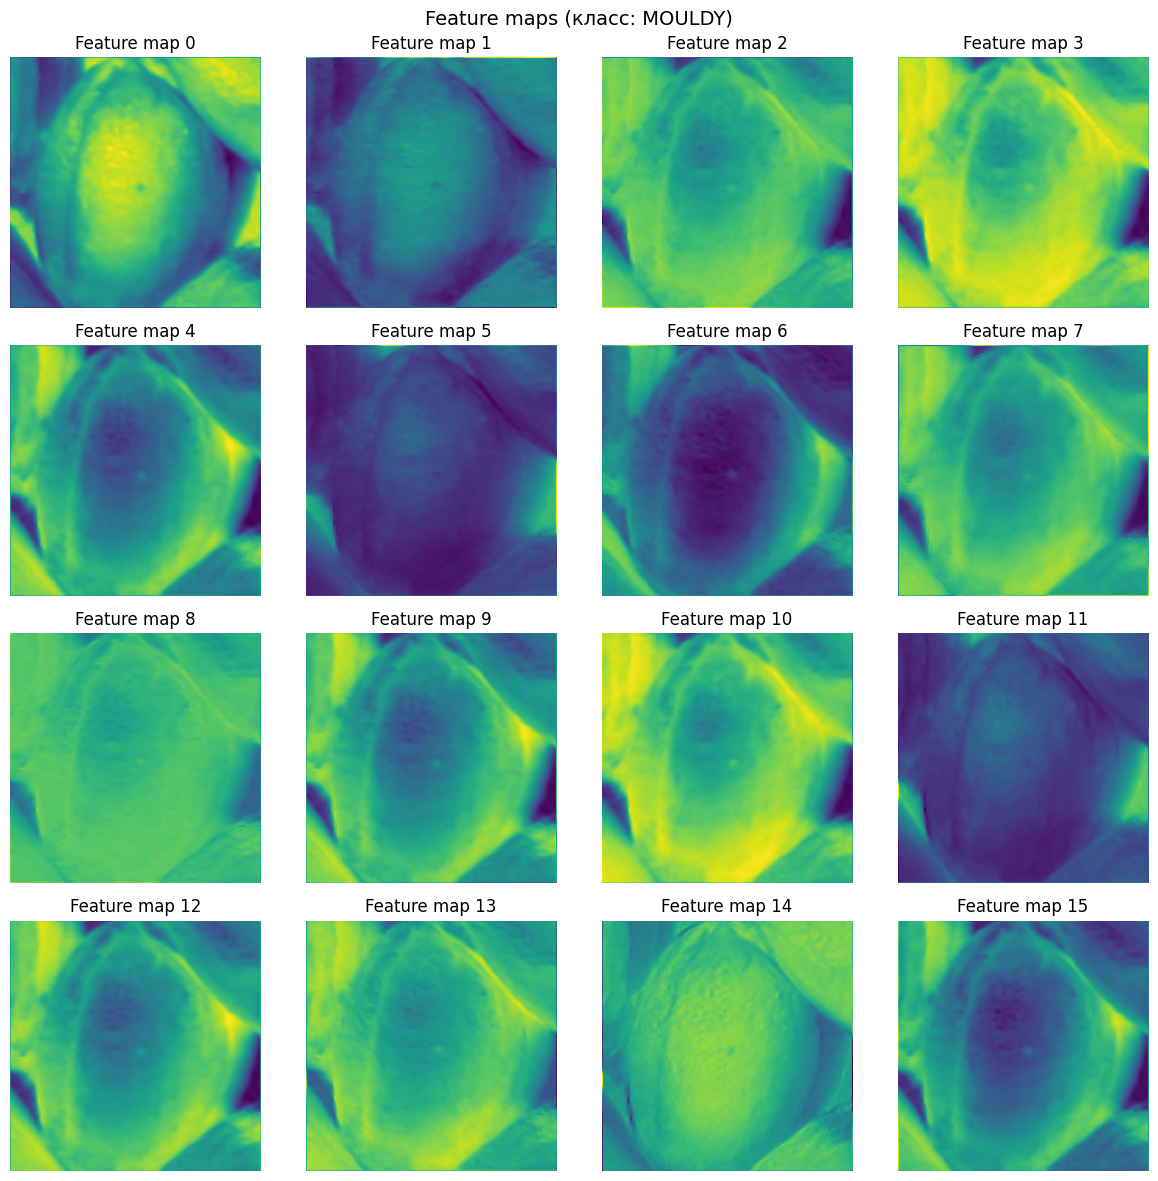

In [19]:
activations = {}

def get_activation(name):
    def hook(module, input, output):
        activations[name] = output.detach()
    return hook

model.features[0][0].register_forward_hook(get_activation('conv1'))

model.eval()
img, label = val_dataset[0]
with torch.no_grad():
    _ = model(img.unsqueeze(0).to(device))

act = activations['conv1'][0].cpu()

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    if i < act.shape[0]:
        ax.imshow(act[i].numpy(), cmap='viridis')
        ax.set_title(f'Feature map {i}')
    ax.axis('off')
plt.suptitle(f'Feature maps (класс: {val_dataset.classes[label]})', fontsize=14)
plt.tight_layout()
plt.show()

# **Задание 9.1 — Ответ**

На фильтрах видны детекторы градиентов: одни реагируют на горизонтальные переходы яркости, другие — на вертикальные и диагональные, третьи — на цветовые границы. На feature maps видно, что разные фильтры активируются в разных областях: одни подсвечивают края зерна, другие — текстуру поверхности, третьи — цветовые пятна. Большое положительное значение означает, что фильтр «нашёл» искомый признак в этой позиции.

# **10. Grad-CAM**

**Ячейка 10.1 — Класс GradCAM**

In [20]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()
        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output[0, 0].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam[0, 0].cpu().numpy()

**Ячейка 10.2 — Grad-CAM на одном изображении**

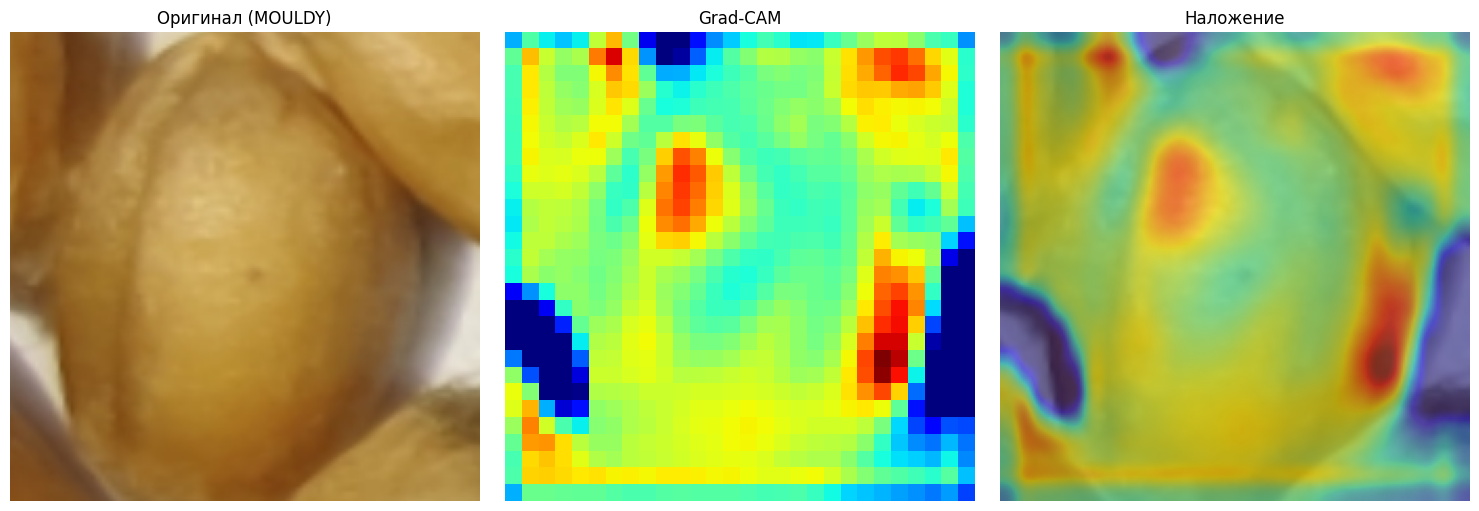

In [21]:
import matplotlib.cm as cm
from PIL import Image

target_layer = model.features[3][0]
grad_cam = GradCAM(model, target_layer)

img, label = val_dataset[0]
input_tensor = img.unsqueeze(0).to(device)
cam = grad_cam.generate(input_tensor)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
img_show = img.permute(1, 2, 0).numpy()
img_show = img_show * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
img_show = np.clip(img_show, 0, 1)

axes[0].imshow(img_show); axes[0].set_title(f'Оригинал ({val_dataset.classes[label]})'); axes[0].axis('off')
axes[1].imshow(cam, cmap='jet'); axes[1].set_title('Grad-CAM'); axes[1].axis('off')

cam_resized = np.array(Image.fromarray(cam).resize(img_show.shape[:2][::-1]))
overlay = np.clip(0.5 * img_show + 0.5 * cm.jet(cam_resized)[:, :, :3], 0, 1)
axes[2].imshow(overlay); axes[2].set_title('Наложение'); axes[2].axis('off')
plt.tight_layout(); plt.show()

**Ячейка 10.3 — Grad-CAM для 5 изображений MOULDY (Задание 10.1)**

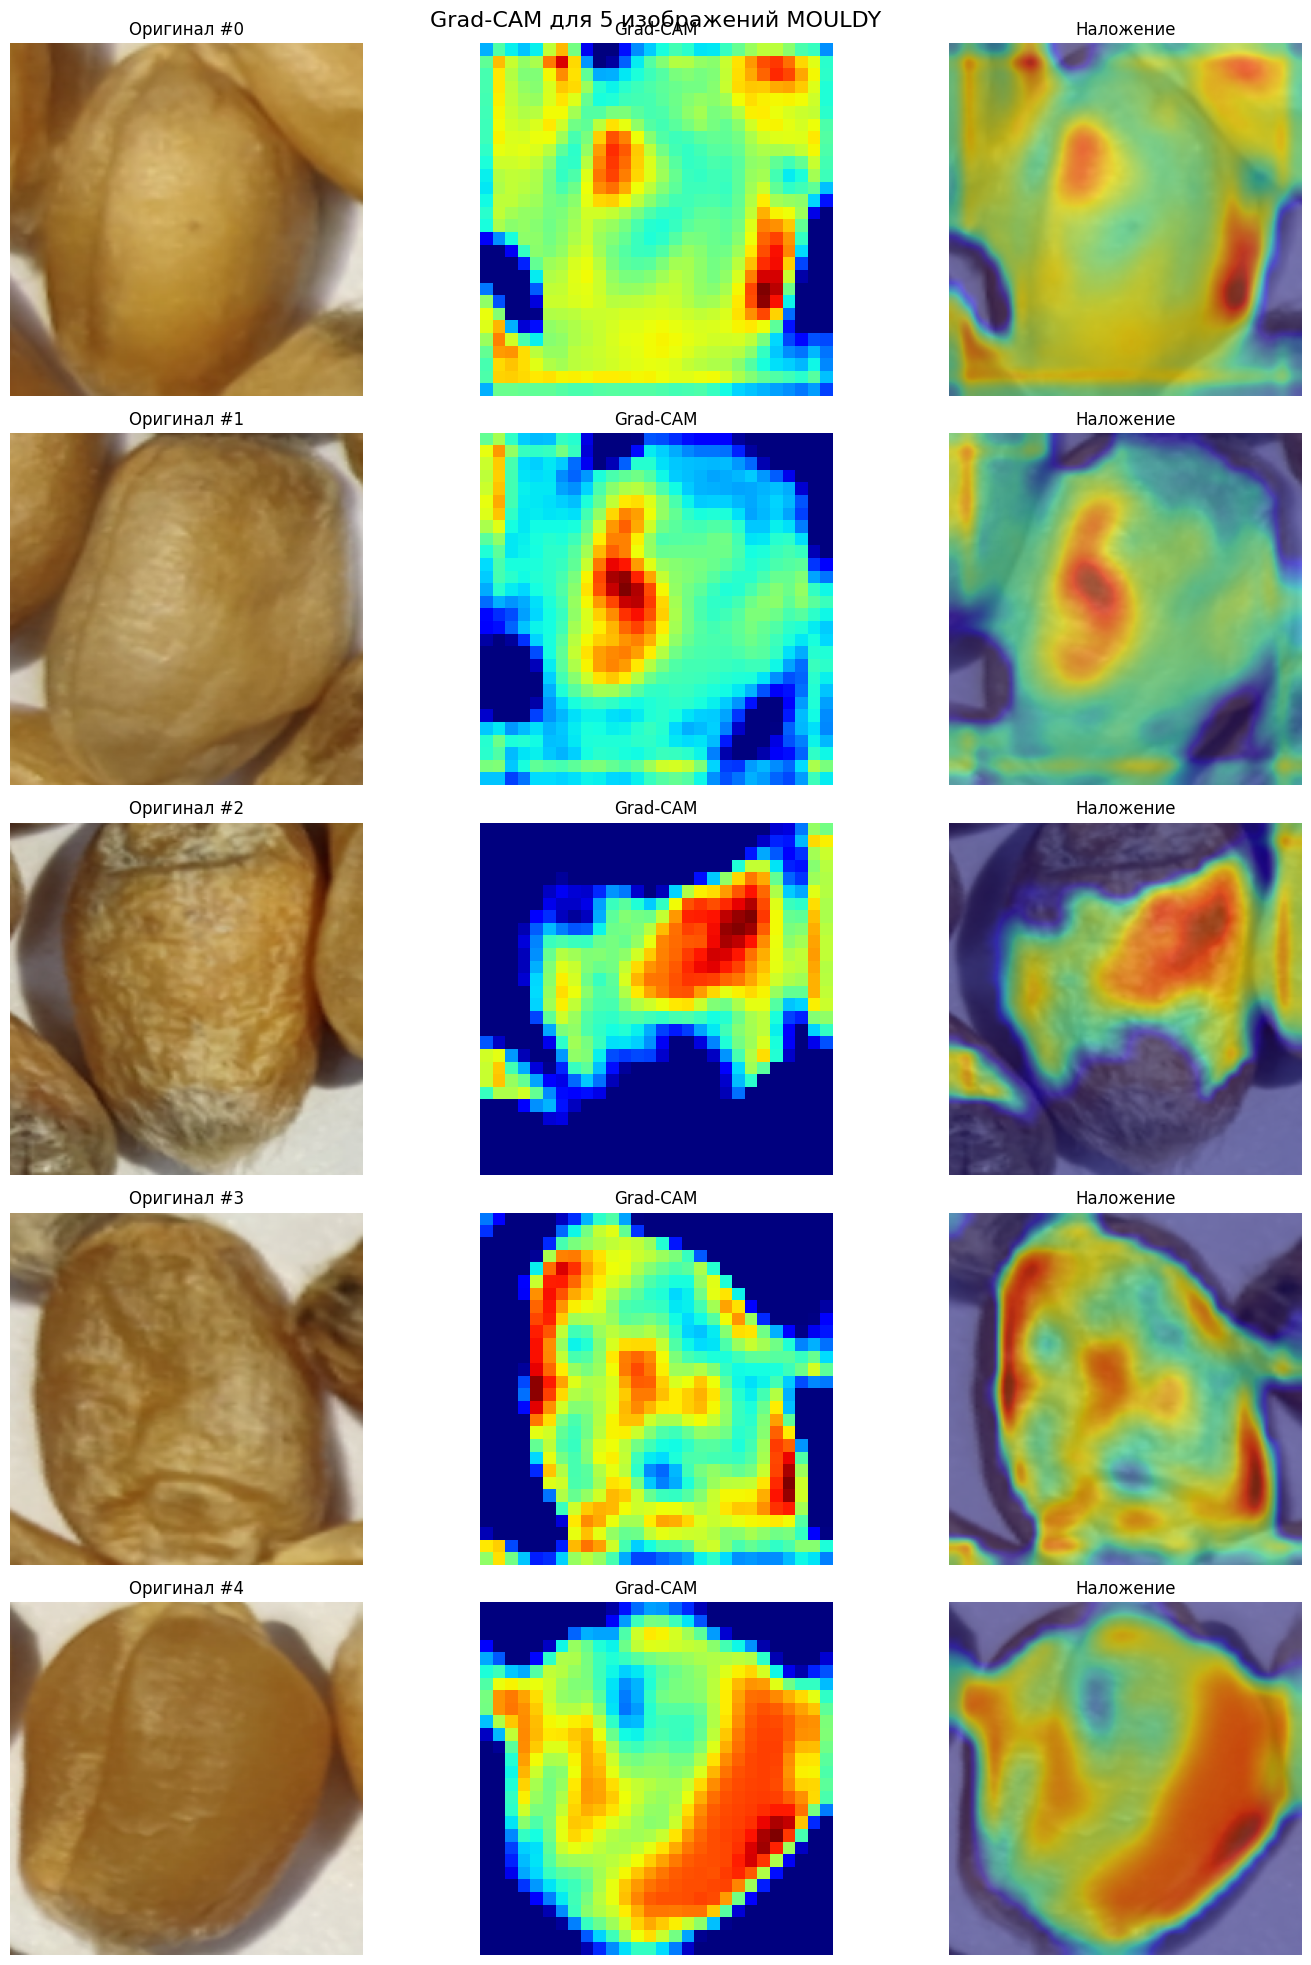

In [22]:
mouldy_idx = [i for i, (_, l) in enumerate(val_dataset)
              if val_dataset.classes[l] == 'MOULDY'][:5]

fig, axes = plt.subplots(len(mouldy_idx), 3, figsize=(15, 4*len(mouldy_idx)))
if len(mouldy_idx) == 1:
    axes = axes.reshape(1, -1)

for row, idx in enumerate(mouldy_idx):
    img, label = val_dataset[idx]
    cam = grad_cam.generate(img.unsqueeze(0).to(device))
    img_show = img.permute(1, 2, 0).numpy()
    img_show = img_show * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_show = np.clip(img_show, 0, 1)

    axes[row, 0].imshow(img_show); axes[row, 0].set_title(f'Оригинал #{idx}'); axes[row, 0].axis('off')
    axes[row, 1].imshow(cam, cmap='jet'); axes[row, 1].set_title('Grad-CAM'); axes[row, 1].axis('off')
    cam_resized = np.array(Image.fromarray(cam).resize(img_show.shape[:2][::-1]))
    overlay = np.clip(0.5 * img_show + 0.5 * cm.jet(cam_resized)[:, :, :3], 0, 1)
    axes[row, 2].imshow(overlay); axes[row, 2].set_title('Наложение'); axes[row, 2].axis('off')

plt.suptitle('Grad-CAM для 5 изображений MOULDY', fontsize=16)
plt.tight_layout(); plt.show()

# **11. Data Augmentation — визуализация**

**Ячейка 11.1 — Аугментации**

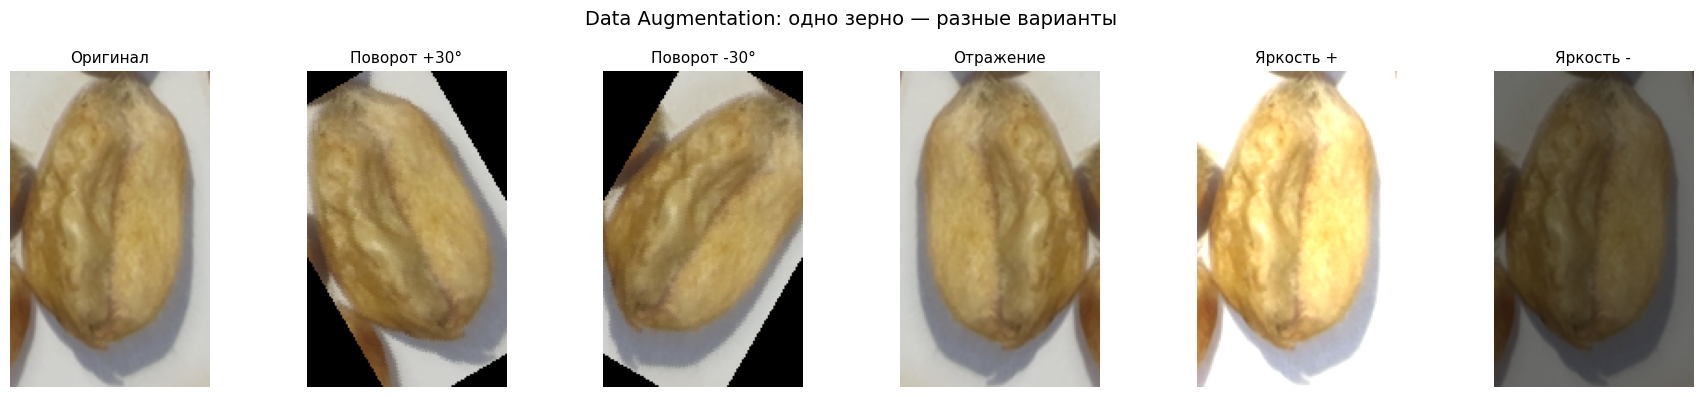

In [26]:
import torch
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms, datasets

# Берём оригинальное изображение без аугментаций
raw_img, raw_label = datasets.ImageFolder(
    os.path.join(DATA_ROOT, 'train'),
    transform=transforms.ToTensor()
)[0]

# Все аугментации работают с PIL-изображением и возвращают PIL.
# ToTensor применяем уже после аугментации — вручную.
img_pil = transforms.ToPILImage()(raw_img)

augmentations = [
    ('Оригинал',     lambda im: im),
    ('Поворот +30°', lambda im: transforms.functional.rotate(im, 30)),
    ('Поворот -30°', lambda im: transforms.functional.rotate(im, -30)),
    ('Отражение',    lambda im: transforms.functional.hflip(im)),
    ('Яркость +',    lambda im: transforms.functional.adjust_brightness(im, 1.5)),
    ('Яркость -',    lambda im: transforms.functional.adjust_brightness(im, 0.5)),
]

fig, axes = plt.subplots(1, 6, figsize=(18, 4))
for i, (name, aug) in enumerate(augmentations):
    im_aug = aug(img_pil)                          # PIL → PIL
    im_tensor = transforms.ToTensor()(im_aug)      # PIL → tensor [0..1]
    axes[i].imshow(im_tensor.permute(1, 2, 0).clamp(0, 1))
    axes[i].set_title(name, fontsize=11)
    axes[i].axis('off')

plt.suptitle('Data Augmentation: одно зерно — разные варианты', fontsize=14)
plt.tight_layout()
plt.show()

# **12. Оценка лучшей модели**

Считаем метрики для ResNet-18.

**Ячейка 12.1 — Метрики и confusion matrix**

Accuracy:  0.9167
Precision: 0.9000
Recall:    1.0000
F1:        0.9474


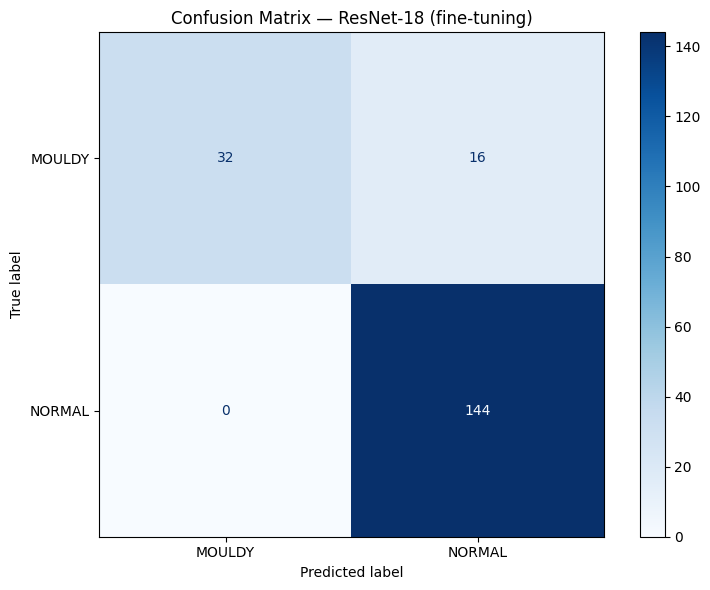

In [27]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay)

best_model = resnet
test_loss, test_acc, y_prob, y_true = evaluate(best_model, val_loader, criterion_rn, device)
y_pred = (y_prob > 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1:        {f1_score(y_true, y_pred):.4f}")

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=val_dataset.classes)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues")
plt.title("Confusion Matrix — ResNet-18 (fine-tuning)")
plt.tight_layout(); plt.show()

# **Задание 12.1 — Ответ**

Confusion matrix показывает, сколько изображений каждого класса модель предсказала верно/неверно. Обычно путает MOULDY с NORMAL (false negatives) — модель «пропускает» плесень.

Почему recall важнее precision: recall = TP / (TP + FN) — доля найденных плесневелых зёрен. Если модель пропустит плесневелое зерно (FN), оно попадёт в посев и заразит урожай. Ложное срабатывание (FP) — здоровое зерно отправят в отходы, это дешевле, чем потерять урожай.